In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyodbc

In [2]:
from sqlalchemy import create_engine

connection_string = (
    "mssql+pyodbc://@localhost/AdventureWorks2022"
    "?driver=ODBC+Driver+18+for+SQL+Server"
    "&trusted_connection=yes"
    "&TrustServerCertificate=yes"
)

engine = create_engine(connection_string)

In [3]:
from sqlalchemy import text

with engine.connect() as connection:
    result = connection.execute(
        text("SELECT COUNT(*) AS TotalOrders FROM Sales.SalesOrderHeader")
    )

    print(result.fetchone()[0])

31465


In [4]:
query = """
SELECT
    YEAR(OrderDate) AS SalesYear,
    COUNT(*) AS NumberOfOrders,
    SUM(TotalDue) AS Revenue,
    AVG(TotalDue) AS AverageOrderValue
FROM Sales.SalesOrderHeader
GROUP BY YEAR(OrderDate)
ORDER BY SalesYear;
"""

df_yearly_sales = pd.read_sql(query, engine)

df_yearly_sales

,SalesYear,NumberOfOrders,Revenue,AverageOrderValue
0,2011,1607,1.415570e+07,8808.7738
1,2012,3915,3.767570e+07,9623.4228
2,2013,14182,4.896589e+07,3452.6786
3,2014,11761,2.241950e+07,1906.2578


In [5]:
df_yearly_sales.describe()

,SalesYear,NumberOfOrders,Revenue,AverageOrderValue
count,4.000000,4.000000,4.000000e+00,4.000000
mean,2012.500000,7866.250000,3.080420e+07,5947.783250
std,1.290994,6051.125591,1.554070e+07,3840.792809
min,2011.000000,1607.000000,1.415570e+07,1906.257800
25%,2011.750000,3338.000000,2.035355e+07,3066.073400
50%,2012.500000,7838.000000,3.004760e+07,6130.726200
75%,2013.250000,12366.250000,4.049825e+07,9012.436050
max,2014.000000,14182.000000,4.896589e+07,9623.422800


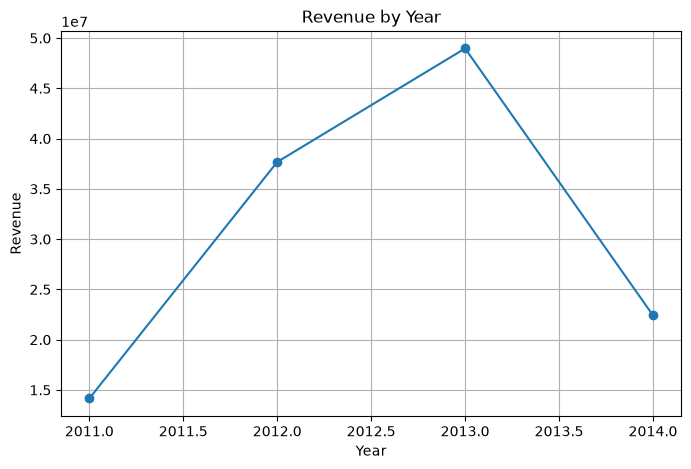

In [6]:
plt.figure(figsize=(8, 5))

plt.plot(
    df_yearly_sales["SalesYear"],
    df_yearly_sales["Revenue"],
    marker="o"
)

plt.title("Revenue by Year")
plt.xlabel("Year")
plt.ylabel("Revenue")
plt.grid(True)

plt.show()

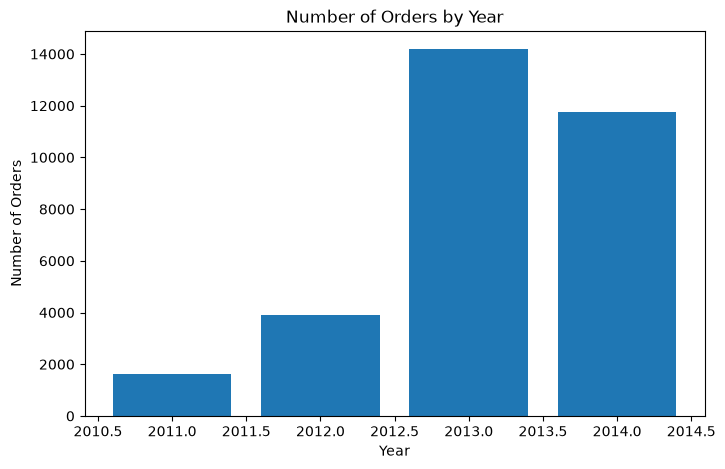

In [7]:
plt.figure(figsize=(8, 5))

plt.bar(
    df_yearly_sales["SalesYear"],
    df_yearly_sales["NumberOfOrders"]
)

plt.title("Number of Orders by Year")
plt.xlabel("Year")
plt.ylabel("Number of Orders")

plt.show()

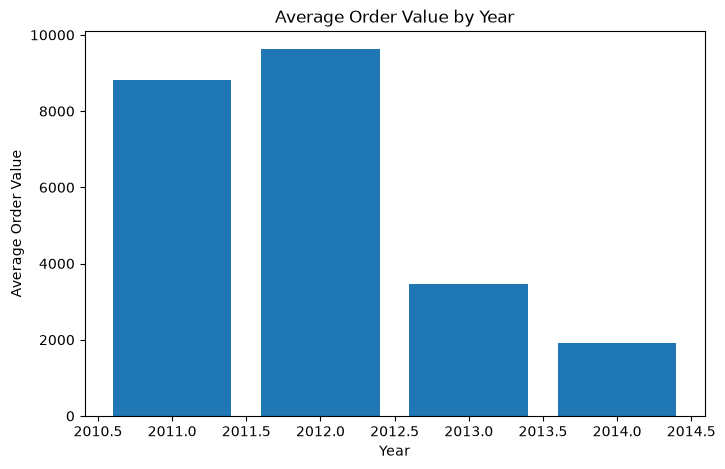

In [8]:
plt.figure(figsize=(8, 5))

plt.bar(
    df_yearly_sales["SalesYear"],
    df_yearly_sales["AverageOrderValue"]
)

plt.title("Average Order Value by Year")
plt.xlabel("Year")
plt.ylabel("Average Order Value")

plt.show()

In [9]:
query_orders = """
SELECT
    SalesOrderID,
    OrderDate,
    TotalDue
FROM Sales.SalesOrderHeader;
"""

df_orders = pd.read_sql(query_orders, engine)

df_orders.head()

,SalesOrderID,OrderDate,TotalDue
0,43659,2011-05-31,23153.2339
1,43660,2011-05-31,1457.3288
2,43661,2011-05-31,36865.8012
3,43662,2011-05-31,32474.9324
4,43663,2011-05-31,472.3108


In [10]:
df_orders["SalesYear"] = df_orders["OrderDate"].dt.year

df_orders.head()

,SalesOrderID,OrderDate,TotalDue,SalesYear
0,43659,2011-05-31,23153.2339,2011
1,43660,2011-05-31,1457.3288,2011
2,43661,2011-05-31,36865.8012,2011
3,43662,2011-05-31,32474.9324,2011
4,43663,2011-05-31,472.3108,2011


In [11]:
df_orders.groupby("SalesYear")["TotalDue"].sum()

SalesYear
2011    1.415570e+07
2012    3.767570e+07
2013    4.896589e+07
2014    2.241950e+07
Name: TotalDue, dtype: float64

In [12]:
df_revenue_by_year = (
    df_orders
    .groupby("SalesYear")["TotalDue"]
    .sum()
    .reset_index(name="Revenue")
)

df_revenue_by_year

,SalesYear,Revenue
0,2011,1.415570e+07
1,2012,3.767570e+07
2,2013,4.896589e+07
3,2014,2.241950e+07


In [13]:
df_yearly = (
    df_orders
    .groupby("SalesYear")
    .agg(
        NumberOfOrders=("SalesOrderID", "count"),
        Revenue=("TotalDue", "sum"),
        AverageOrderValue=("TotalDue", "mean")
    )
    .reset_index()
)

df_yearly

,SalesYear,NumberOfOrders,Revenue,AverageOrderValue
0,2011,1607,1.415570e+07,8808.773818
1,2012,3915,3.767570e+07,9623.422813
2,2013,14182,4.896589e+07,3452.678604
3,2014,11761,2.241950e+07,1906.257828


In [14]:
df_yearly.sort_values(
    by="Revenue",
    ascending=False
)

,SalesYear,NumberOfOrders,Revenue,AverageOrderValue
2,2013,14182,4.896589e+07,3452.678604
1,2012,3915,3.767570e+07,9623.422813
3,2014,11761,2.241950e+07,1906.257828
0,2011,1607,1.415570e+07,8808.773818


In [15]:
df_yearly_sorted = (
    df_yearly
    .sort_values(by="Revenue", ascending=False)
    .reset_index(drop=True)
)

df_yearly_sorted

,SalesYear,NumberOfOrders,Revenue,AverageOrderValue
0,2013,14182,4.896589e+07,3452.678604
1,2012,3915,3.767570e+07,9623.422813
2,2014,11761,2.241950e+07,1906.257828
3,2011,1607,1.415570e+07,8808.773818


In [16]:
df_yearly_sorted.head(2)

,SalesYear,NumberOfOrders,Revenue,AverageOrderValue
0,2013,14182,4.896589e+07,3452.678604
1,2012,3915,3.767570e+07,9623.422813


In [17]:
query_products = """
SELECT
    p.Name AS ProductName,
    SUM(sod.LineTotal) AS Revenue
FROM Sales.SalesOrderDetail AS sod
INNER JOIN Production.Product AS p
    ON sod.ProductID = p.ProductID
GROUP BY p.Name
ORDER BY Revenue DESC;
"""

df_products = pd.read_sql(query_products, engine)

df_products.head(10)

,ProductName,Revenue
0,"Mountain-200 Black, 38",4.400593e+06
1,"Mountain-200 Black, 42",4.009495e+06
2,"Mountain-200 Silver, 38",3.693678e+06
3,"Mountain-200 Silver, 42",3.438479e+06
4,"Mountain-200 Silver, 46",3.434257e+06
5,"Mountain-200 Black, 46",3.309673e+06
6,"Road-250 Black, 44",2.516857e+06
7,"Road-250 Black, 48",2.347656e+06
8,"Road-250 Black, 52",2.012448e+06
9,"Road-150 Red, 56",1.847819e+06


In [18]:
query_products = """
SELECT
    p.Name AS ProductName,
    SUM(sod.OrderQty) AS UnitsSold,
    SUM(sod.LineTotal) AS Revenue
FROM Sales.SalesOrderDetail AS sod
INNER JOIN Production.Product AS p
    ON sod.ProductID = p.ProductID
GROUP BY p.Name
ORDER BY Revenue DESC;
"""

df_products = pd.read_sql(query_products, engine)

df_products.head(10)

,ProductName,UnitsSold,Revenue
0,"Mountain-200 Black, 38",2977,4.400593e+06
1,"Mountain-200 Black, 42",2664,4.009495e+06
2,"Mountain-200 Silver, 38",2394,3.693678e+06
3,"Mountain-200 Silver, 42",2234,3.438479e+06
4,"Mountain-200 Silver, 46",2216,3.434257e+06
5,"Mountain-200 Black, 46",2111,3.309673e+06
6,"Road-250 Black, 44",1642,2.516857e+06
7,"Road-250 Black, 48",1498,2.347656e+06
8,"Road-250 Black, 52",1245,2.012448e+06
9,"Road-150 Red, 56",664,1.847819e+06


In [19]:
df_products["AverageUnitPrice"] = (
    df_products["Revenue"] / df_products["UnitsSold"]
)

df_products.head(10)

,ProductName,UnitsSold,Revenue,AverageUnitPrice
0,"Mountain-200 Black, 38",2977,4.400593e+06,1478.197111
1,"Mountain-200 Black, 42",2664,4.009495e+06,1505.065601
2,"Mountain-200 Silver, 38",2394,3.693678e+06,1542.889735
3,"Mountain-200 Silver, 42",2234,3.438479e+06,1539.157950
4,"Mountain-200 Silver, 46",2216,3.434257e+06,1549.754938
5,"Mountain-200 Black, 46",2111,3.309673e+06,1567.822462
6,"Road-250 Black, 44",1642,2.516857e+06,1532.799826
7,"Road-250 Black, 48",1498,2.347656e+06,1567.193560
8,"Road-250 Black, 52",1245,2.012448e+06,1616.423916
9,"Road-150 Red, 56",664,1.847819e+06,2782.859380


In [20]:
df_products.sort_values(
    by="AverageUnitPrice",
    ascending=False
).head(10)

,ProductName,UnitsSold,Revenue,AverageUnitPrice
16,"Road-150 Red, 48",493,1.540803e+06,3125.361181
21,"Road-150 Red, 52",458,1.415564e+06,3090.750245
24,"Road-150 Red, 44",437,1.340420e+06,3067.322522
11,"Road-150 Red, 62",600,1.769097e+06,2948.494480
9,"Road-150 Red, 56",664,1.847819e+06,2782.859380
31,"Mountain-100 Silver, 44",601,1.217210e+06,2025.308419
38,"Mountain-100 Silver, 48",505,1.019657e+06,2019.122774
22,"Mountain-100 Black, 44",678,1.365852e+06,2014.531531
26,"Mountain-100 Silver, 38",642,1.291869e+06,2012.256543
28,"Mountain-100 Black, 48",616,1.234276e+06,2003.694855


In [21]:
total_revenue = df_products["Revenue"].sum()

total_revenue

np.float64(109846381.399888)

In [22]:
df_products["RevenueShare"] = (
    df_products["Revenue"] / total_revenue * 100
)

df_products.head(10)

,ProductName,UnitsSold,Revenue,AverageUnitPrice,RevenueShare
0,"Mountain-200 Black, 38",2977,4.400593e+06,1478.197111,4.006134
1,"Mountain-200 Black, 42",2664,4.009495e+06,1505.065601,3.650093
2,"Mountain-200 Silver, 38",2394,3.693678e+06,1542.889735,3.362585
3,"Mountain-200 Silver, 42",2234,3.438479e+06,1539.157950,3.130261
4,"Mountain-200 Silver, 46",2216,3.434257e+06,1549.754938,3.126418
5,"Mountain-200 Black, 46",2111,3.309673e+06,1567.822462,3.013002
6,"Road-250 Black, 44",1642,2.516857e+06,1532.799826,2.291252
7,"Road-250 Black, 48",1498,2.347656e+06,1567.193560,2.137217
8,"Road-250 Black, 52",1245,2.012448e+06,1616.423916,1.832057
9,"Road-150 Red, 56",664,1.847819e+06,2782.859380,1.682184


In [23]:
df_products_by_share = (
    df_products
    .sort_values(by="RevenueShare", ascending=False)
    .reset_index(drop=True)
)

df_products_by_share.head(10)

,ProductName,UnitsSold,Revenue,AverageUnitPrice,RevenueShare
0,"Mountain-200 Black, 38",2977,4.400593e+06,1478.197111,4.006134
1,"Mountain-200 Black, 42",2664,4.009495e+06,1505.065601,3.650093
2,"Mountain-200 Silver, 38",2394,3.693678e+06,1542.889735,3.362585
3,"Mountain-200 Silver, 42",2234,3.438479e+06,1539.157950,3.130261
4,"Mountain-200 Silver, 46",2216,3.434257e+06,1549.754938,3.126418
5,"Mountain-200 Black, 46",2111,3.309673e+06,1567.822462,3.013002
6,"Road-250 Black, 44",1642,2.516857e+06,1532.799826,2.291252
7,"Road-250 Black, 48",1498,2.347656e+06,1567.193560,2.137217
8,"Road-250 Black, 52",1245,2.012448e+06,1616.423916,1.832057
9,"Road-150 Red, 56",664,1.847819e+06,2782.859380,1.682184


In [24]:
top_10_revenue_share = (
    df_products_by_share
    .head(10)["RevenueShare"]
    .sum()
)

top_10_revenue_share

np.float64(28.23120241462557)

In [25]:
top_10_revenue = (
    df_products_by_share
    .head(10)["Revenue"]
    .sum()
)

top_10_revenue

np.float64(31010954.278143995)

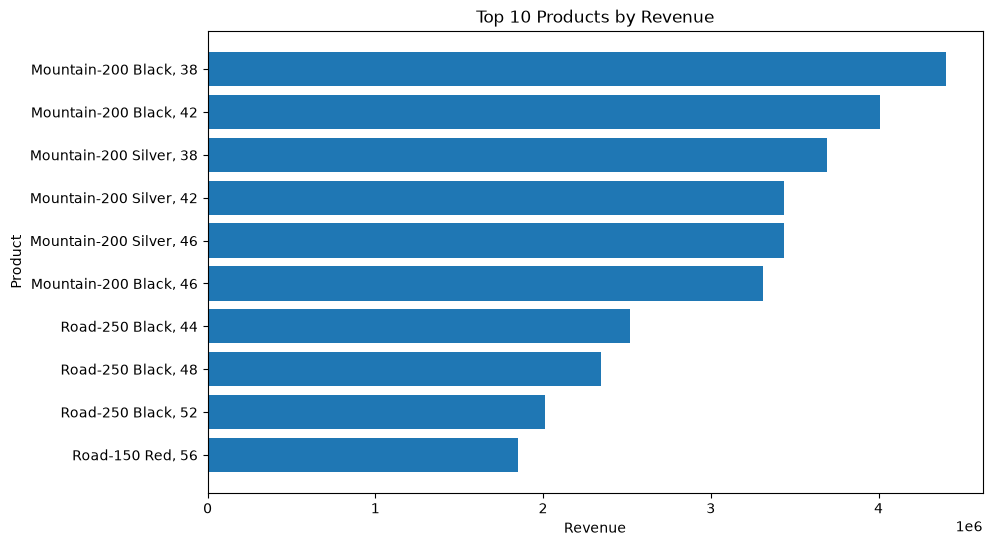

In [26]:
top_10_products = df_products_by_share.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_products["ProductName"],
    top_10_products["Revenue"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.gca().invert_yaxis()

plt.show()

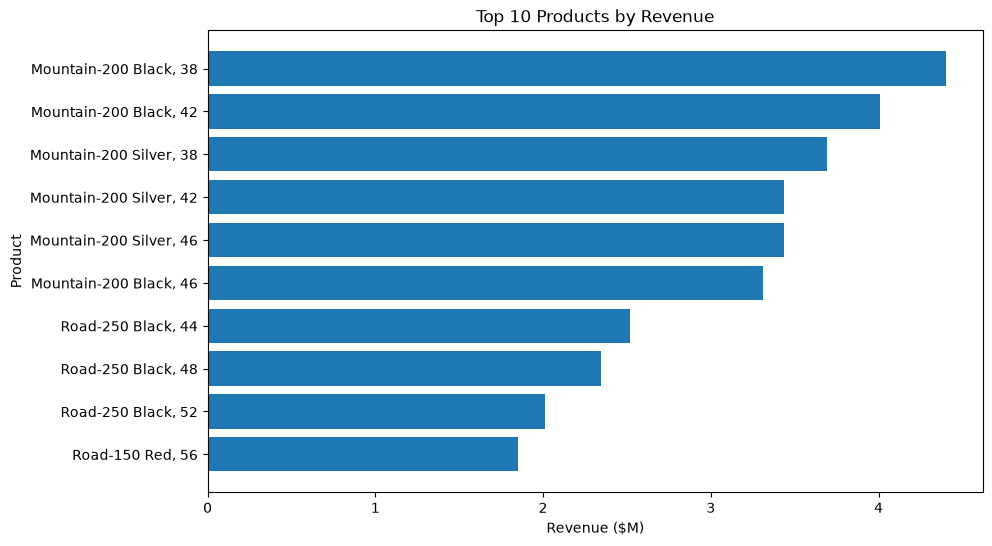

In [27]:
top_10_products = df_products_by_share.head(10).copy()

top_10_products["RevenueMillions"] = (
    top_10_products["Revenue"] / 1_000_000
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_products["ProductName"],
    top_10_products["RevenueMillions"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue ($M)")
plt.ylabel("Product")

plt.gca().invert_yaxis()

plt.show()

In [28]:
query_categories = """
SELECT
    pc.Name AS Category,
    SUM(sod.LineTotal) AS Revenue
FROM Sales.SalesOrderDetail AS sod
INNER JOIN Production.Product AS p
    ON sod.ProductID = p.ProductID
INNER JOIN Production.ProductSubcategory AS psc
    ON p.ProductSubcategoryID = psc.ProductSubcategoryID
INNER JOIN Production.ProductCategory AS pc
    ON psc.ProductCategoryID = pc.ProductCategoryID
GROUP BY pc.Name
ORDER BY Revenue DESC;
"""

df_categories = pd.read_sql(query_categories, engine)

df_categories

,Category,Revenue
0,Bikes,9.465117e+07
1,Components,1.180259e+07
2,Clothing,2.120543e+06
3,Accessories,1.272073e+06


In [29]:
total_category_revenue = df_categories["Revenue"].sum()

df_categories["RevenueShare"] = (
    df_categories["Revenue"] / total_category_revenue * 100
)

df_categories

,Category,Revenue,RevenueShare
0,Bikes,9.465117e+07,86.166855
1,Components,1.180259e+07,10.744635
2,Clothing,2.120543e+06,1.930462
3,Accessories,1.272073e+06,1.158047


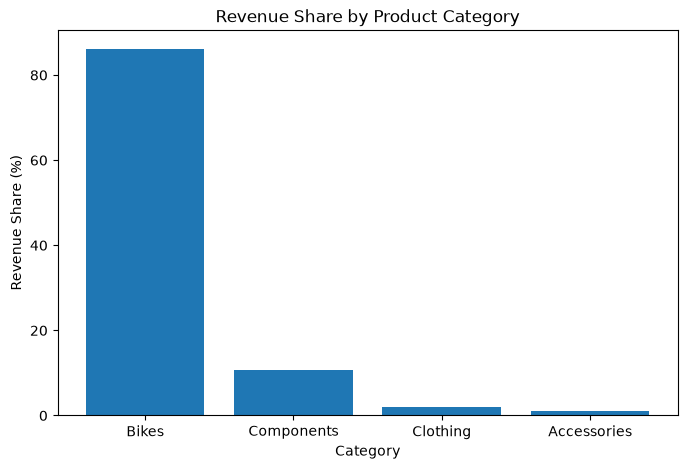

In [30]:
plt.figure(figsize=(8, 5))

plt.bar(
    df_categories["Category"],
    df_categories["RevenueShare"]
)

plt.title("Revenue Share by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue Share (%)")

plt.show()

In [31]:
query_bike_subcategories = """
SELECT
    psc.Name AS Subcategory,
    SUM(sod.OrderQty) AS UnitsSold,
    SUM(sod.LineTotal) AS Revenue
FROM Sales.SalesOrderDetail AS sod
INNER JOIN Production.Product AS p
    ON sod.ProductID = p.ProductID
INNER JOIN Production.ProductSubcategory AS psc
    ON p.ProductSubcategoryID = psc.ProductSubcategoryID
INNER JOIN Production.ProductCategory AS pc
    ON psc.ProductCategoryID = pc.ProductCategoryID
WHERE pc.Name = 'Bikes'
GROUP BY psc.Name
ORDER BY Revenue DESC;
"""

df_bike_subcategories = pd.read_sql(
    query_bike_subcategories,
    engine
)

df_bike_subcategories

,Subcategory,UnitsSold,Revenue
0,Road Bikes,47196,4.390944e+07
1,Mountain Bikes,28321,3.644544e+07
2,Touring Bikes,14751,1.429629e+07


In [32]:
total_bike_revenue = df_bike_subcategories["Revenue"].sum()

df_bike_subcategories["RevenueShare"] = (
    df_bike_subcategories["Revenue"] / total_bike_revenue * 100
)

df_bike_subcategories

,Subcategory,UnitsSold,Revenue,RevenueShare
0,Road Bikes,47196,4.390944e+07,46.390801
1,Mountain Bikes,28321,3.644544e+07,38.505010
2,Touring Bikes,14751,1.429629e+07,15.104188


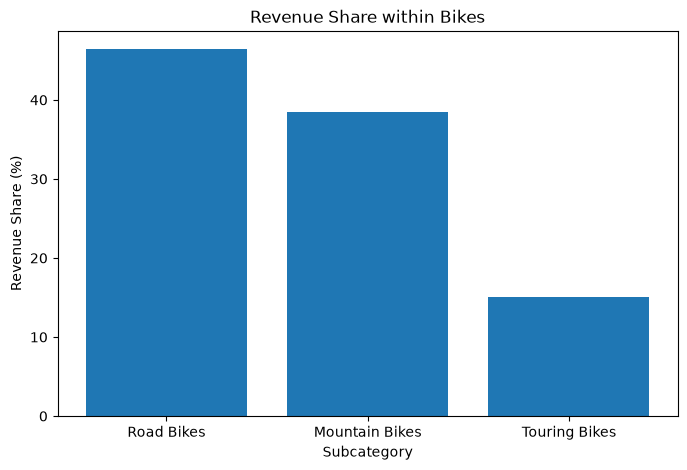

In [33]:
plt.figure(figsize=(8, 5))

plt.bar(
    df_bike_subcategories["Subcategory"],
    df_bike_subcategories["RevenueShare"]
)

plt.title("Revenue Share within Bikes")
plt.xlabel("Subcategory")
plt.ylabel("Revenue Share (%)")

plt.show()

In [34]:
df_bike_subcategories["AverageRevenuePerUnit"] = (
    df_bike_subcategories["Revenue"] /
    df_bike_subcategories["UnitsSold"]
)

df_bike_subcategories

,Subcategory,UnitsSold,Revenue,RevenueShare,AverageRevenuePerUnit
0,Road Bikes,47196,4.390944e+07,46.390801,930.363537
1,Mountain Bikes,28321,3.644544e+07,38.505010,1286.869953
2,Touring Bikes,14751,1.429629e+07,15.104188,969.174379


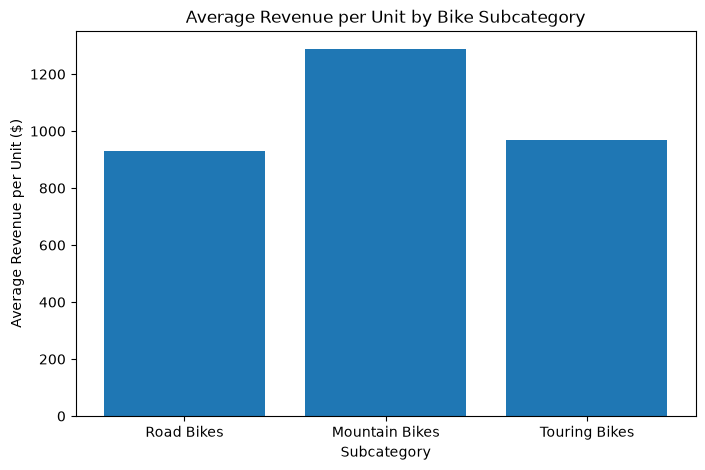

In [35]:
plt.figure(figsize=(8, 5))

plt.bar(
    df_bike_subcategories["Subcategory"],
    df_bike_subcategories["AverageRevenuePerUnit"]
)

plt.title("Average Revenue per Unit by Bike Subcategory")
plt.xlabel("Subcategory")
plt.ylabel("Average Revenue per Unit ($)")

plt.show()

In [36]:
df_orders["YearMonth"] = (
    df_orders["OrderDate"]
    .dt.to_period("M")
)

df_orders[["OrderDate", "YearMonth"]].head()

,OrderDate,YearMonth
0,2011-05-31,2011-05
1,2011-05-31,2011-05
2,2011-05-31,2011-05
3,2011-05-31,2011-05
4,2011-05-31,2011-05


In [37]:
df_monthly_sales = (
    df_orders
    .groupby("YearMonth")
    .agg(
        NumberOfOrders=("SalesOrderID", "count"),
        Revenue=("TotalDue", "sum"),
        AverageOrderValue=("TotalDue", "mean")
    )
    .reset_index()
)

df_monthly_sales.head(10)

,YearMonth,NumberOfOrders,Revenue,AverageOrderValue
0,2011-05,43,5.670209e+05,13186.533716
1,2011-06,141,5.070965e+05,3596.428858
2,2011-07,231,2.292183e+06,9922.869623
3,2011-08,250,2.800576e+06,11202.304689
4,2011-09,157,5.547916e+05,3533.704511
5,2011-10,327,5.156270e+06,15768.408346
6,2011-11,230,8.153130e+05,3544.839197
7,2011-12,228,1.462449e+06,6414.249555
8,2012-01,336,4.458337e+06,13268.861442
9,2012-02,219,1.649052e+06,7529.917352


In [38]:
df_monthly_sales["Month"] = (
    df_monthly_sales["YearMonth"]
    .dt.to_timestamp()
)

df_monthly_sales[["YearMonth", "Month"]].head()

,YearMonth,Month
0,2011-05,2011-05-01
1,2011-06,2011-06-01
2,2011-07,2011-07-01
3,2011-08,2011-08-01
4,2011-09,2011-09-01


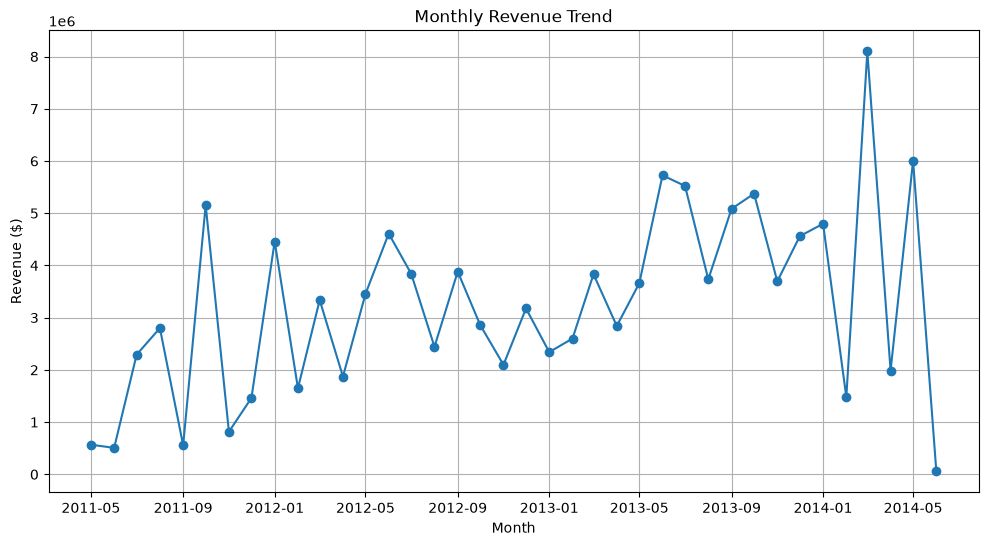

In [39]:
plt.figure(figsize=(12, 6))

plt.plot(
    df_monthly_sales["Month"],
    df_monthly_sales["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.grid(True)

plt.show()

In [40]:
df_orders["OrderDate"].max()

Timestamp('2014-06-30 00:00:00')

In [41]:
df_monthly_sales.tail(10)

,YearMonth,NumberOfOrders,Revenue,AverageOrderValue,Month
28,2013-09,1791,5.083505e+06,2838.361439,2013-09-01
29,2013-10,1968,5.374376e+06,2730.882084,2013-10-01
30,2013-11,2103,3.694668e+06,1756.855920,2013-11-01
31,2013-12,2050,4.560577e+06,2224.671754,2013-12-01
32,2014-01,2141,4.798028e+06,2241.021892,2014-01-01
33,2014-02,1756,1.478213e+06,841.807114,2014-02-01
34,2014-03,2399,8.097036e+06,3375.171452,2014-03-01
35,2014-04,2115,1.985886e+06,938.953262,2014-04-01
36,2014-05,2411,6.006183e+06,2491.158528,2014-05-01
37,2014-06,939,5.415148e+04,57.669306,2014-06-01


In [42]:
df_orders[
    (df_orders["OrderDate"].dt.year == 2014) &
    (df_orders["OrderDate"].dt.month == 6)
].sort_values(
    by="TotalDue",
    ascending=False
).head(10)

,SalesOrderID,OrderDate,TotalDue,SalesYear,YearMonth
31363,75022,2014-06-27,272.3273,2014,2014-06
31120,74779,2014-06-19,229.0444,2014,2014-06
31186,74845,2014-06-22,227.9063,2014,2014-06
30921,74580,2014-06-13,219.8840,2014,2014-06
30866,74525,2014-06-11,216.1270,2014,2014-06
31101,74760,2014-06-19,215.1656,2014,2014-06
30857,74516,2014-06-11,214.3479,2014,2014-06
31464,75123,2014-06-30,209.9169,2014,2014-06
31301,74960,2014-06-25,205.4969,2014,2014-06
31041,74700,2014-06-17,182.5681,2014,2014-06


In [43]:
df_june_2014 = df_orders[
    (df_orders["OrderDate"].dt.year == 2014) &
    (df_orders["OrderDate"].dt.month == 6)
]

df_june_2014.groupby("OrderDate").agg(
    NumberOfOrders=("SalesOrderID", "count"),
    Revenue=("TotalDue", "sum")
)

,NumberOfOrders,Revenue
OrderDate,,
2014-06-01,34,1673.2913
2014-06-02,34,1985.4981
2014-06-03,24,1437.9702
2014-06-04,29,1360.9299
2014-06-05,30,1894.6891
2014-06-06,29,1456.9545
2014-06-07,51,2791.0880
2014-06-08,26,1155.3888
2014-06-09,28,1624.9144


In [44]:
query_may_june_products = """
SELECT
    soh.OrderDate,
    p.Name AS ProductName,
    sod.OrderQty,
    sod.LineTotal
FROM Sales.SalesOrderHeader AS soh
INNER JOIN Sales.SalesOrderDetail AS sod
    ON soh.SalesOrderID = sod.SalesOrderID
INNER JOIN Production.Product AS p
    ON sod.ProductID = p.ProductID
WHERE soh.OrderDate >= '2014-05-01'
  AND soh.OrderDate < '2014-07-01';
"""

df_may_june_products = pd.read_sql(
    query_may_june_products,
    engine
)

df_may_june_products.head()

,OrderDate,ProductName,OrderQty,LineTotal
0,2014-05-01,"ML Road Frame-W - Yellow, 48",1,356.898
1,2014-05-01,"ML Road Frame-W - Yellow, 38",1,356.898
2,2014-05-01,"Touring-1000 Blue, 46",1,1430.442
3,2014-05-01,Front Brakes,3,191.700
4,2014-05-01,"Short-Sleeve Classic Jersey, L",4,129.576


In [45]:
df_may_june_products["Month"] = (
    df_may_june_products["OrderDate"]
    .dt.to_period("M")
)

df_may_june_products[["OrderDate", "Month"]].head()

,OrderDate,Month
0,2014-05-01,2014-05
1,2014-05-01,2014-05
2,2014-05-01,2014-05
3,2014-05-01,2014-05
4,2014-05-01,2014-05


In [46]:
df_may_june_summary = (
    df_may_june_products
    .groupby("Month")
    .agg(
        UnitsSold=("OrderQty", "sum"),
        ProductRevenue=("LineTotal", "sum")
    )
    .reset_index()
)

df_may_june_summary

,Month,UnitsSold,ProductRevenue
0,2014-05,15884,5.366675e+06
1,2014-06,2130,4.900584e+04


In [47]:
df_june_products = (
    df_may_june_products[
        df_may_june_products["Month"] == "2014-06"
    ]
    .groupby("ProductName")
    .agg(
        UnitsSold=("OrderQty", "sum"),
        Revenue=("LineTotal", "sum")
    )
    .sort_values(
        by="UnitsSold",
        ascending=False
    )
    .reset_index()
)

df_june_products.head(10)

,ProductName,UnitsSold,Revenue
0,Mountain Tire Tube,182,908.18
1,Patch Kit/8 Patches,175,400.75
2,Water Bottle - 30 oz.,161,803.39
3,Road Tire Tube,152,606.48
4,Fender Set - Mountain,103,2263.94
5,"Sport-100 Helmet, Blue",94,3289.06
6,AWC Logo Cap,93,836.07
7,"Sport-100 Helmet, Black",91,3184.09
8,Touring Tire Tube,90,449.10
9,Mountain Bottle Cage,80,799.20


In [48]:
query_june_categories = """
SELECT
    pc.Name AS Category,
    SUM(sod.OrderQty) AS UnitsSold,
    SUM(sod.LineTotal) AS Revenue
FROM Sales.SalesOrderHeader AS soh
INNER JOIN Sales.SalesOrderDetail AS sod
    ON soh.SalesOrderID = sod.SalesOrderID
INNER JOIN Production.Product AS p
    ON sod.ProductID = p.ProductID
INNER JOIN Production.ProductSubcategory AS psc
    ON p.ProductSubcategoryID = psc.ProductSubcategoryID
INNER JOIN Production.ProductCategory AS pc
    ON psc.ProductCategoryID = pc.ProductCategoryID
WHERE soh.OrderDate >= '2014-06-01'
  AND soh.OrderDate < '2014-07-01'
GROUP BY pc.Name
ORDER BY Revenue DESC;
"""

df_june_categories = pd.read_sql(
    query_june_categories,
    engine
)

df_june_categories

,Category,UnitsSold,Revenue
0,Accessories,1711,32728.72
1,Clothing,419,16277.12


In [49]:
query_may_june_categories = """
SELECT
    YEAR(soh.OrderDate) AS SalesYear,
    MONTH(soh.OrderDate) AS SalesMonth,
    pc.Name AS Category,
    SUM(sod.OrderQty) AS UnitsSold,
    SUM(sod.LineTotal) AS Revenue
FROM Sales.SalesOrderHeader AS soh
INNER JOIN Sales.SalesOrderDetail AS sod
    ON soh.SalesOrderID = sod.SalesOrderID
INNER JOIN Production.Product AS p
    ON sod.ProductID = p.ProductID
INNER JOIN Production.ProductSubcategory AS psc
    ON p.ProductSubcategoryID = psc.ProductSubcategoryID
INNER JOIN Production.ProductCategory AS pc
    ON psc.ProductCategoryID = pc.ProductCategoryID
WHERE soh.OrderDate >= '2014-05-01'
  AND soh.OrderDate < '2014-07-01'
GROUP BY
    YEAR(soh.OrderDate),
    MONTH(soh.OrderDate),
    pc.Name
ORDER BY
    SalesMonth,
    Revenue DESC;
"""

df_may_june_categories = pd.read_sql(
    query_may_june_categories,
    engine
)

df_may_june_categories

,SalesYear,SalesMonth,Category,UnitsSold,Revenue
0,2014,5,Bikes,4321,4.565083e+06
1,2014,5,Components,2553,5.771386e+05
2,2014,5,Clothing,3967,1.196678e+05
3,2014,5,Accessories,5043,1.047860e+05
4,2014,6,Accessories,1711,3.272872e+04
5,2014,6,Clothing,419,1.627712e+04


In [50]:
query_order_type = """
SELECT
    YEAR(OrderDate) AS SalesYear,
    MONTH(OrderDate) AS SalesMonth,
    OnlineOrderFlag,
    COUNT(*) AS NumberOfOrders,
    SUM(TotalDue) AS Revenue
FROM Sales.SalesOrderHeader
WHERE OrderDate >= '2014-05-01'
  AND OrderDate < '2014-07-01'
GROUP BY
    YEAR(OrderDate),
    MONTH(OrderDate),
    OnlineOrderFlag
ORDER BY
    SalesMonth,
    OnlineOrderFlag;
"""

df_order_type = pd.read_sql(
    query_order_type,
    engine
)

df_order_type

,SalesYear,SalesMonth,OnlineOrderFlag,NumberOfOrders,Revenue
0,2014,5,False,179,3.850112e+06
1,2014,5,True,2232,2.156072e+06
2,2014,6,True,939,5.415148e+04


In [51]:
query_category_order_type = """
SELECT
    MONTH(soh.OrderDate) AS SalesMonth,
    soh.OnlineOrderFlag,
    pc.Name AS Category,
    SUM(sod.OrderQty) AS UnitsSold,
    SUM(sod.LineTotal) AS Revenue
FROM Sales.SalesOrderHeader AS soh
INNER JOIN Sales.SalesOrderDetail AS sod
    ON soh.SalesOrderID = sod.SalesOrderID
INNER JOIN Production.Product AS p
    ON sod.ProductID = p.ProductID
INNER JOIN Production.ProductSubcategory AS psc
    ON p.ProductSubcategoryID = psc.ProductSubcategoryID
INNER JOIN Production.ProductCategory AS pc
    ON psc.ProductCategoryID = pc.ProductCategoryID
WHERE soh.OrderDate >= '2014-05-01'
  AND soh.OrderDate < '2014-07-01'
GROUP BY
    MONTH(soh.OrderDate),
    soh.OnlineOrderFlag,
    pc.Name
ORDER BY
    SalesMonth,
    OnlineOrderFlag,
    Revenue DESC;
"""

df_category_order_type = pd.read_sql(
    query_category_order_type,
    engine
)

df_category_order_type

,SalesMonth,OnlineOrderFlag,Category,UnitsSold,Revenue
0,5,False,Bikes,3135,2.716129e+06
1,5,False,Components,2553,5.771386e+05
2,5,False,Clothing,2999,8.364249e+04
3,5,False,Accessories,1573,3.856916e+04
4,5,True,Bikes,1186,1.848954e+06
5,5,True,Accessories,3470,6.621685e+04
6,5,True,Clothing,968,3.602535e+04
7,6,True,Accessories,1711,3.272872e+04
8,6,True,Clothing,419,1.627712e+04


In [52]:
df_ytd_comparison = (
    df_orders[
        (df_orders["OrderDate"].dt.month <= 5) &
        (df_orders["SalesYear"].isin([2013, 2014]))
    ]
    .groupby("SalesYear")
    .agg(
        NumberOfOrders=("SalesOrderID", "count"),
        Revenue=("TotalDue", "sum"),
        AverageOrderValue=("TotalDue", "mean")
    )
    .reset_index()
)

df_ytd_comparison

,SalesYear,NumberOfOrders,Revenue,AverageOrderValue
0,2013,2022,1.527068e+07,7552.266309
1,2014,10822,2.236535e+07,2066.655594


In [ ]:
revenue_yoy = (
    (df_ytd_comparison.loc[1, "Revenue"]
     - df_ytd_comparison.loc[0, "Revenue"])
    / df_ytd_comparison.loc[0, "Revenue"]
    * 100
)

orders_yoy = (
    (df_ytd_comparison.loc[1, "NumberOfOrders"]
     - df_ytd_comparison.loc[0, "NumberOfOrders"])
    / df_ytd_comparison.loc[0, "NumberOfOrders"]
    * 100
)

aov_yoy = (
    (df_ytd_comparison.loc[1, "AverageOrderValue"]
     - df_ytd_comparison.loc[0, "AverageOrderValue"])
    / df_ytd_comparison.loc[0, "AverageOrderValue"]
    * 100
)

print(f"Revenue YoY: {revenue_yoy:.2f}%")
print(f"Orders YoY: {orders_yoy:.2f}%")
print(f"Average Order Value YoY: {aov_yoy:.2f}%")

Revenue YoY: 46.46%
Orders YoY: 435.21%
Average Order Value YoY: -72.64%


## Temporal Analysis - Key Insights

- Revenue peaked in 2013 when analyzing full-year totals, but 2014 contains only data through June and should not be directly compared with a complete year.
- A like-for-like comparison of January-May shows that 2014 revenue increased by 46.46% compared with the same period in 2013.
- Order volume increased significantly by 435.21%, while Average Order Value decreased by 72.64%.
- This indicates that 2014 revenue growth was primarily driven by a much higher volume of lower-value orders.
- June 2014 shows a structural shift in the sales mix: non-online orders disappear and sales are limited to Accessories and Clothing, with no Bikes or Components sales recorded.